# Data provenance, coverage and selection
Executed against the delivered CSV results. See ../docs/METHODS.md for model assumptions.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root=Path('..')
print(json.loads((root/'results/data_integrity.json').read_text()))


{'prior_lines': 32434489, 'prior_orders': 3214874, 'product_catalog_rows': 49688, 'order_metadata_rows': 3421083, 'train_lines': 25944305, 'holdout_lines': 6490184, 'duplicate_order_products': 0, 'missing_foreign_keys': 0, 'missing_line_values': 0, 'order_ids_sorted': True}


In [2]:
scope=pd.read_csv(root/'results/scope_summary.csv')
print(scope[['scope','skus','train_line_coverage','heldout_line_coverage','heldout_complete_order_fraction','eligible_heldout_orders','mean_lines_all','mean_lines_eligible']].to_string(index=False))


     scope  skus  train_line_coverage  heldout_line_coverage  heldout_complete_order_fraction  eligible_heldout_orders  mean_lines_all  mean_lines_eligible
compact800   800             0.502853               0.503169                         0.080017                     4801         10.1018             3.292647
coverage90  9149             0.900001               0.899902                         0.530267                    31816         10.1018             7.746260


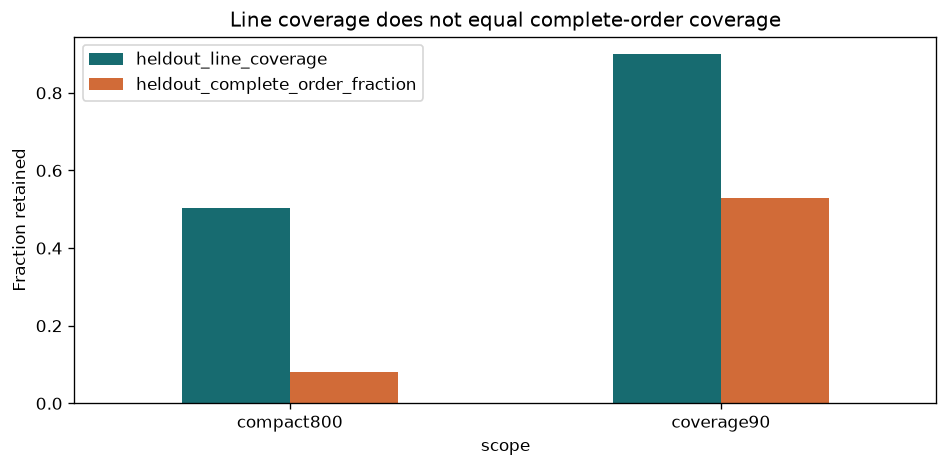

In [3]:
fig,ax=plt.subplots(figsize=(8,4))
scope.set_index('scope')[['heldout_line_coverage','heldout_complete_order_fraction']].plot.bar(ax=ax,color=['#176b70','#d16b38'])
ax.set(ylabel='Fraction retained',title='Line coverage does not equal complete-order coverage')
ax.tick_params(axis='x',rotation=0)
fig.tight_layout()


In [4]:
velocity=pd.read_csv(root/'results/sku_velocity.csv')
print(velocity[['product_id','product_name','zone','train_lines']].head(12).to_string(index=False))
print('All slotting ranks use training lines only; eligibility selection is disclosed, not used to retune storage.')


 product_id           product_name    zone  train_lines
      24852                 Banana chilled       377588
      13176 Bag of Organic Bananas chilled       303561
      21137   Organic Strawberries chilled       211895
      21903   Organic Baby Spinach chilled       193685
      47209   Organic Hass Avocado chilled       170794
      47766        Organic Avocado chilled       141579
      47626            Large Lemon chilled       121997
      16797           Strawberries chilled       114240
      26209                  Limes chilled       112646
      27845     Organic Whole Milk chilled       110313
      27966    Organic Raspberries chilled       109573
      22935   Organic Yellow Onion chilled        90681
All slotting ranks use training lines only; eligibility selection is disclosed, not used to retune storage.
